# Insurance Claim Risk Analysis

This executed notebook inspects the actual artifacts generated by `python main.py`. The main pipeline performs loading, cleaning, feature preparation, cross-validation, evaluation, and prediction with PySpark; this notebook presents the saved outputs without training the model a second time.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUTS = ROOT / 'outputs'
POWERBI = ROOT / 'dashboard' / 'powerbi_data'
RUN = json.loads((OUTPUTS / 'run_metadata.json').read_text(encoding='utf-8'))
print(f"Source rows: {RUN['source_rows']:,}; cleaned rows: {RUN['cleaned_rows']:,}")
print('Risk counts:', RUN['risk_counts'])
print('Mappings:', RUN['mappings'])

Source rows: 1,000; cleaned rows: 1,000
Risk counts: {'Low': 399, 'High': 251, 'Medium': 350}
Mappings: {'claim_type': 'incident_type', 'customer_region': 'policy_state', 'policy_type': 'policy_csl (coverage-limit tier proxy)'}


## Cleaning and constructed target

Question marks/blanks are normalized, duplicates are removed, numeric fields are typed and imputed, claim amount outliers are capped using the IQR rule, and the risk score is mapped into Low, Medium, and High using the observed p40/p75 cutoffs.

In [2]:
predictions = pd.read_csv(ROOT / 'data' / 'processed' / 'cleaned_claims_with_predictions.csv')
print('Prediction table shape:', predictions.shape)
print('Null cells:', int(predictions.isna().sum().sum()))
display(predictions[['risk_level', 'predicted_risk_level']].head())
display(predictions['risk_level'].value_counts().reindex(['Low', 'Medium', 'High']).rename('count'))

Prediction table shape: (1000, 50)
Null cells: 91


,risk_level,predicted_risk_level
0,Low,Low
1,Low,Low
2,Low,Low
3,Low,Low
4,Low,Low


risk_level
Low       399
Medium    350
High      251
Name: count, dtype: int64

## Model evaluation

The majority-class baseline and untuned tree are compared with the best model selected using three-fold cross-validation. F1 on training versus held-out test data provides a basic overfitting check.

In [3]:
metrics = pd.read_csv(OUTPUTS / 'metrics.csv')
per_class = pd.read_csv(OUTPUTS / 'per_class_metrics.csv')
confusion = pd.read_csv(OUTPUTS / 'confusion_matrix.csv', index_col=0)
display(metrics)
display(per_class)
display(confusion)
print('Best parameters:', RUN['best_params'])
print('Train-test F1 gap:', round(RUN['overfit_gap'], 4))
print(RUN['overfit_comment'])
print(RUN['weighted_precision_note'])

,model,majority_class,accuracy,weighted_precision,weighted_recall,weighted_f1
0,majority_class_baseline,Low,0.407407,0.165981,0.407407,0.235867
1,untuned_tree,NaN,0.574074,0.708698,0.574074,0.562182
2,tuned_tree,NaN,0.555556,0.658149,0.555556,0.536964
3,untuned_tree_train,NaN,0.578759,0.748990,0.578759,0.555677
4,tuned_tree_train,NaN,0.572792,0.745327,0.572792,0.548063


,class,precision,recall,f1,support
0,Low,0.911765,0.469697,0.620000,66
1,Medium,0.451327,0.879310,0.596491,58
2,High,0.533333,0.210526,0.301887,38


,Low,Medium,High
actual,,,
Low,31,34,1
Medium,1,51,6
High,2,28,8


Best parameters: {'maxDepth': 5, 'maxBins': 32, 'minInstancesPerNode': 5}
Train-test F1 gap: 0.0111
The train score is higher by 0.0111; this is a modest train/test gap.
Baseline weighted precision=0.7087 exceeds weighted recall=0.5741. Precision is the share of predictions that are correct; recall is the share of actual cases found. The per-class results where precision exceeds recall are: Low: precision=1.000, recall=0.470; High: precision=0.588, recall=0.263; this indicates missed actual cases (false negatives) are lowering recall more than false positives lower precision. The weighted scores are support-weighted, so interpret them with the per-class metrics and confusion matrix.


## Feature importance and risk distributions

Feature names come from Spark VectorAssembler attribute metadata. Charts were created from Spark aggregates and saved as PNG files for the workbook and report.

,feature,importance
0,_imputed_months_as_customer,0.760472
1,_imputed_age,0.072345
2,_imputed_policy_deductable,0.061841
3,_imputed_policy_annual_premium,0.028380
4,_imputed_umbrella_limit,0.027624
5,_imputed_capital-gains,0.019134
6,_imputed_capital-loss,0.016252
7,_imputed_incident_hour_of_the_day,0.013951
8,_imputed_number_of_vehicles_involved,0.000000
9,_imputed_bodily_injuries,0.000000


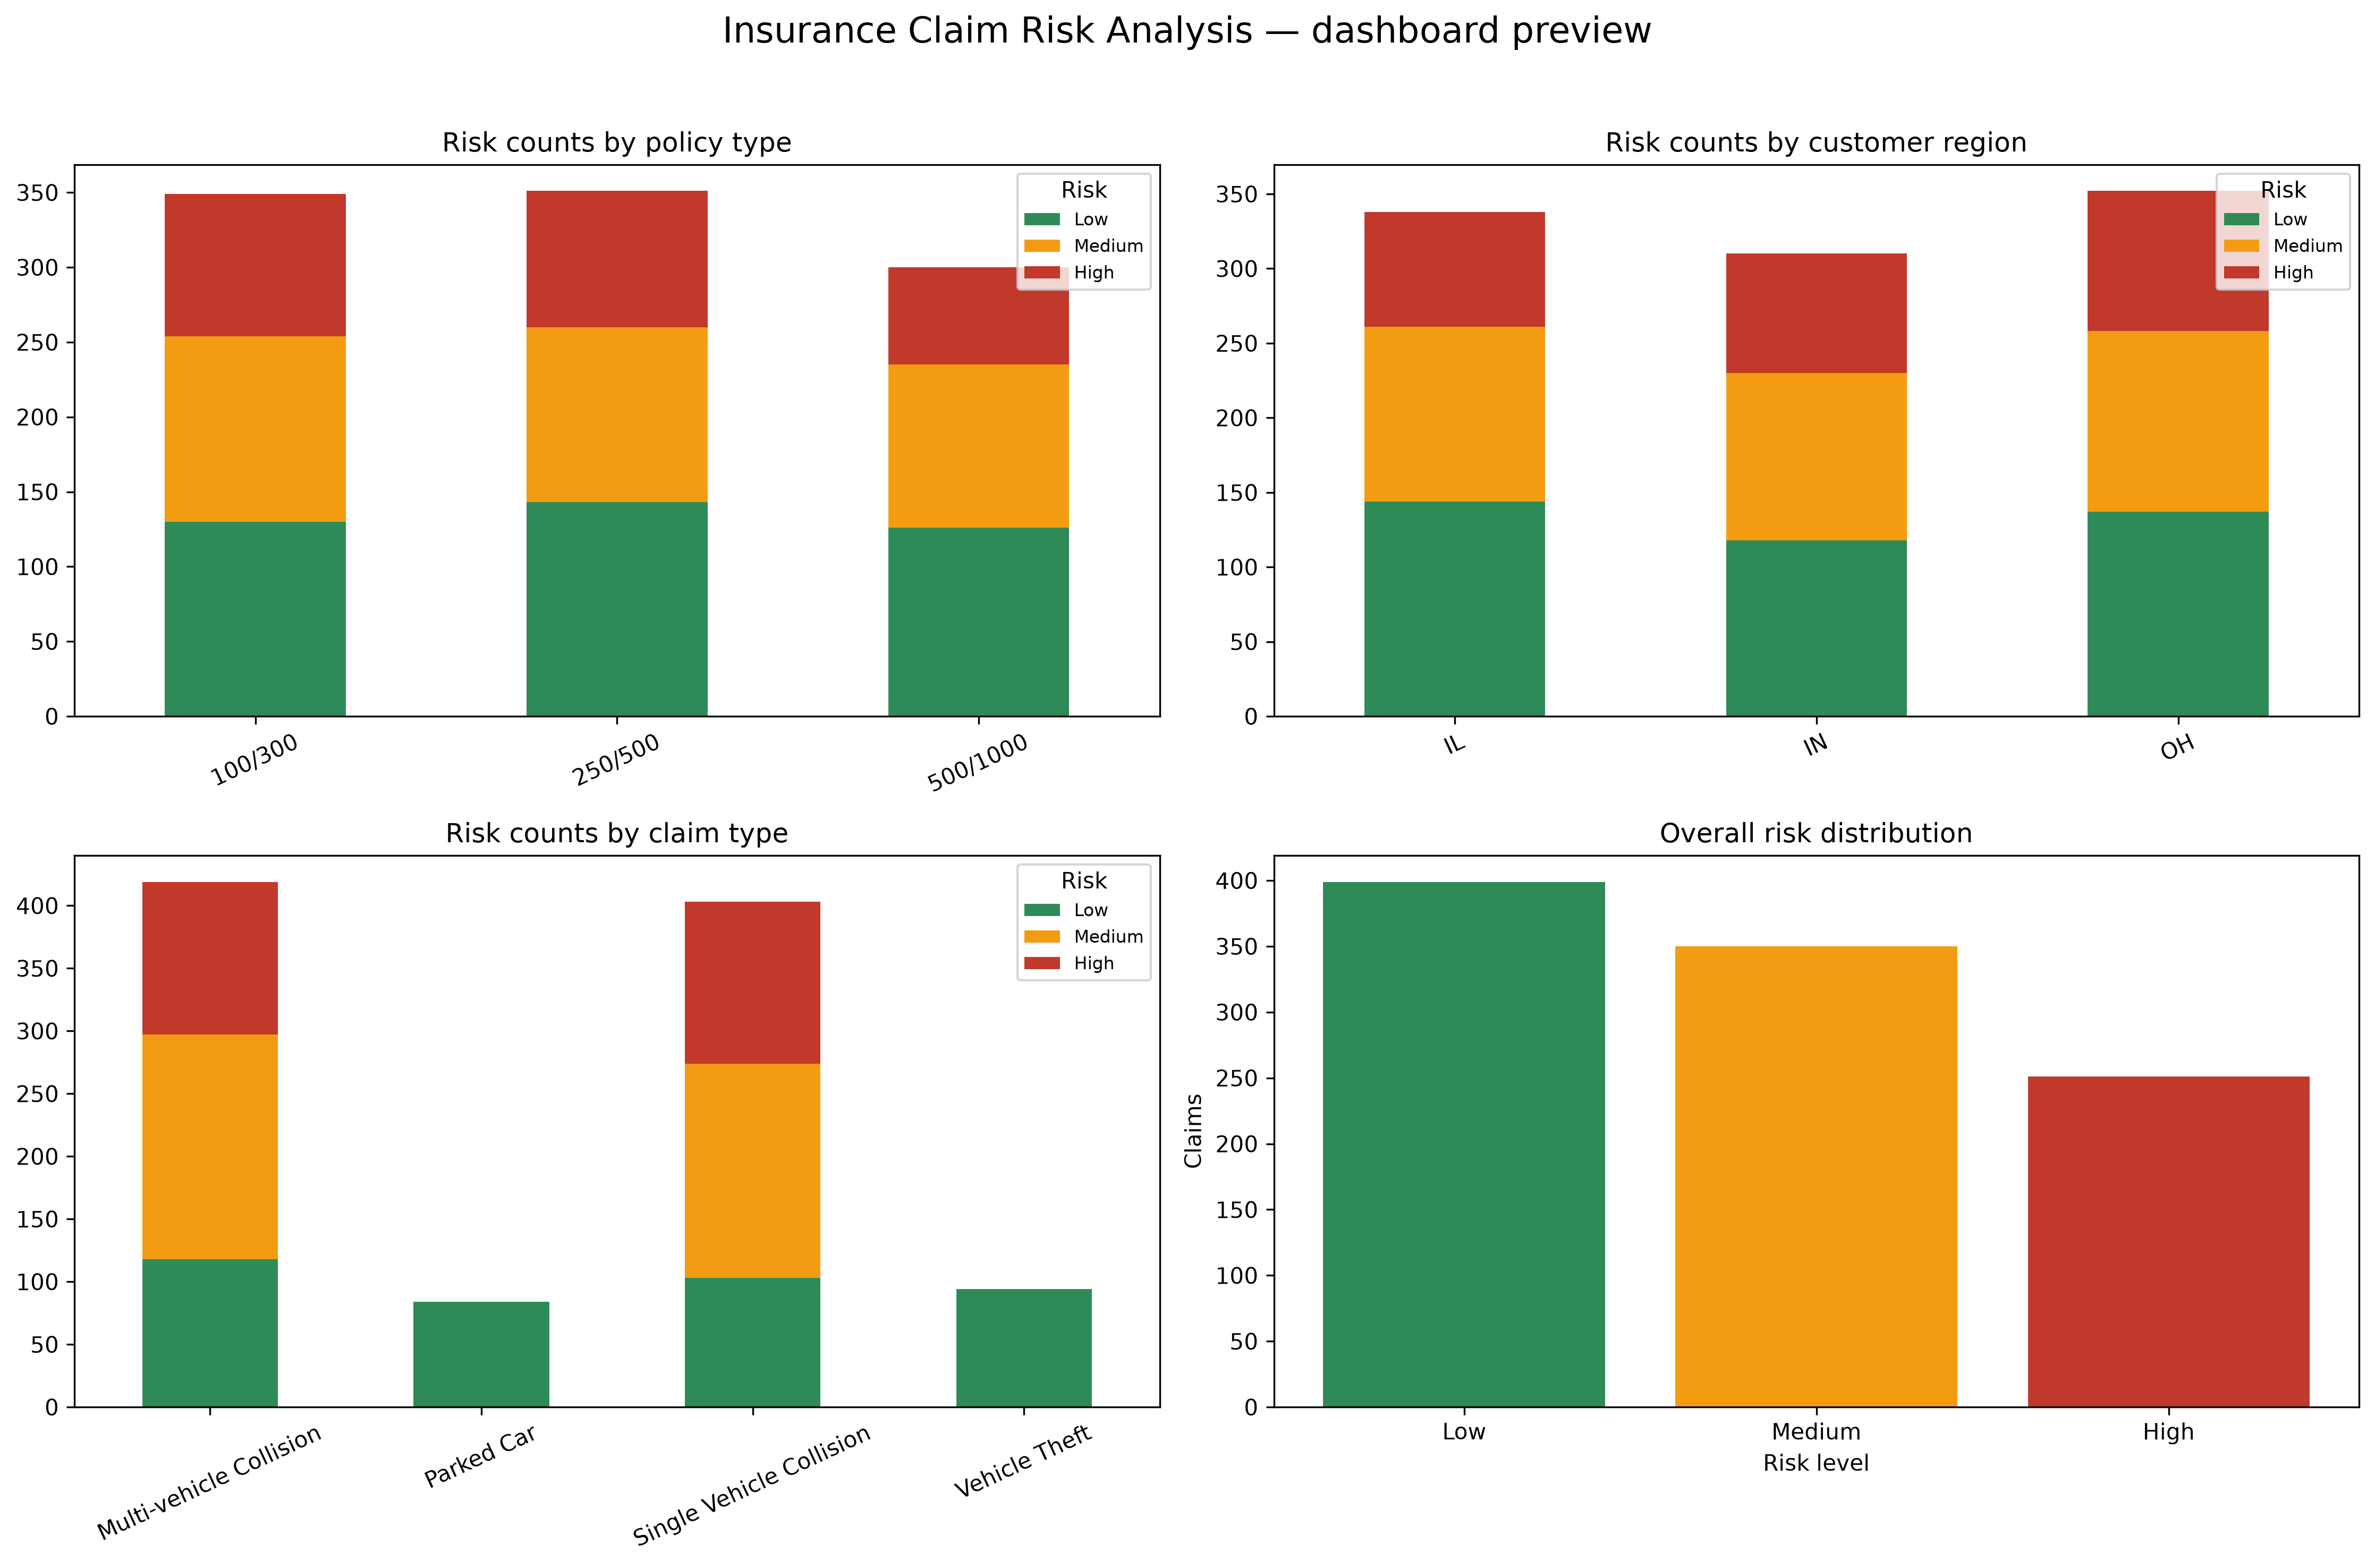

Excel dashboard: C:\Users\Yash Mishra\OneDrive\Desktop\Spark Project\dashboard\Insurance_Claim_Risk_Dashboard.xlsx


In [4]:
importance = pd.read_csv(OUTPUTS / 'feature_importance.csv')
display(importance.head(15))
display(Image(filename=str(ROOT / 'dashboard' / 'dashboard_preview.png')))
print('Excel dashboard:', ROOT / 'dashboard' / 'Insurance_Claim_Risk_Dashboard.xlsx')

## Interpretation and limitations

The target is a heuristic derived from claim amount, incident severity, and the fraud indicator, not independently verified future risk. These target-derived fields are explicitly excluded from model features. `policy_type` is a proxy derived from `policy_csl`; the held-out random split is not external or temporal validation. See `README.md` and the generated DOCX report for full details.